<h3 style="color:skyblue">Mitigating Algorithmic Bias with DB-VAEs ⚖️</h3>

<p>This notebook explores the Debiasing Variational Autoencoder (DB-VAE). Standard CNNs can inherit biases from training data, performing poorly on under-represented groups. The DB-VAE architecture uses an encoder to learn latent features and adaptively resamples data to ensure the model sees "rare" features more frequently.
Learning Objectives:</p>
<ul>
<li>Variational Encoding: Implement an encoder that predicts latent means (mu) and log-variances (log Sigma) rather than fixed points.</li>
<li>Reparameterization: Use the sampling trick (z = mu + sigma ° epsilon) to keep the network end-to-end trainable.</li>
<li>Adaptive Resampling: Build an automated system that uses latent distributions to recompute sampling probabilities and "debias" the training process.</li>
<li>Supervised Latent Variables: Integrate a classification head (z_0) directly into the VAE structure.</li>
</ul>

In [1]:
import os
import random
import IPython
import functools
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from pathlib import Path

# Import torch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn


# Check that we are using a GPU, if not switch runtimes
#   using Runtime > Change Runtime Type > GPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    cudnn.benchmark = True
else:
  raise ValueError("GPU is not available. Change Colab runtime.")

<p style="color:orange">Use Comet ML to track experiments</p>

In [2]:
## Comet ML
!pip install comet_ml --quiet
import comet_ml

# TODO: ENTER YOUR API KEY HERE!! instructions above
COMET_API_KEY = "xq9Un6kijjcpQ808AB95N1ubf"
assert COMET_API_KEY != "", "Please insert your Comet API Key"

# MIT introduction to deep learning package
!pip install mitdeeplearning --quiet
import mitdeeplearning as mdl

I0000 00:00:1778777485.558855    6123 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778777486.891218    6123 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
CACHE_DIR = Path.home() / ".cache" / "mitdeeplearning"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Get the training data: both images from CelebA and ImageNet
path_to_training_data = CACHE_DIR.joinpath("train_face.h5")

# Create a simple check to avoid re-downloading
if path_to_training_data.is_file():
    print(f"Using cached training data from {path_to_training_data}")
else:
    print(f"Downloading training data to {path_to_training_data}")
    url = "https://www.dropbox.com/s/hlz8atheyozp1yx/train_face.h5?dl=1"
    torch.hub.download_url_to_file(url, path_to_training_data)

# Instantiate a TrainingDatasetLoader using the downloaded dataset
channels_last = False
loader = mdl.lab2.TrainingDatasetLoader(
    path_to_training_data, channels_last=channels_last
)

Using cached training data from /home/anon/.cache/mitdeeplearning/train_face.h5
Opening /home/anon/.cache/mitdeeplearning/train_face.h5
Loading data into memory...


In [4]:
number_of_training_examples = loader.get_train_size()
(images, labels) = loader.get_batch(100)
number_of_training_examples

109914

In [5]:
B, C, H, W = images.shape
images.shape

(100, 3, 64, 64)

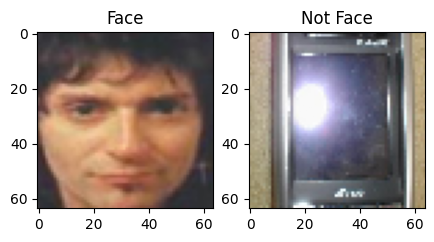

In [ ]:
### Examining the CelebA training dataset ###
# 54957 valid face images
# 54957 invalid non-face images

face_images = images[np.where(labels == 1)[0]].transpose(0, 2, 3, 1)
not_face_images = images[np.where(labels == 0)[0]].transpose(0, 2, 3, 1)

idx_face = 2
idx_not_face = 5

plt.figure(figsize=(5, 5))
plt.subplot(1, 2, 1)
plt.imshow(face_images[idx_face])
plt.title("Face")
plt.grid(False)

plt.subplot(1, 2, 2)
plt.imshow(not_face_images[idx_not_face])
plt.title("Not Face")
plt.grid(False)